<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-09/mnist-trees.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

In [ ]:
#| code-fold: true
#| code-summary: Load supporting course files when running in Colab
from pathlib import Path
from urllib.request import urlretrieve
for name in ['lecture09_data.py']:
    target = Path(name)
    if not target.exists():
        target.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve('https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-scientific-discovery/main/notebooks/lecture-09/' + name, target)

# Three methods for handwritten digits

We compare a decision tree, random forest and small dense neural network on MNIST images. Every method receives the same 784 pixel brightnesses, the same fitting images and the same test images. We inspect validation performance before opening the test results, then display predictions on the same objects.

Keep `lecture09_data.py` beside the notebook. It loads the original MNIST files and checks their checksums. The download is about 12 MB and is cached. MNIST is described by [LeCun et al.](https://doi.org/10.1109/5.726791).

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import balanced_accuracy_score, root_mean_squared_error, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
SEED = 1975
Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

from sklearn.metrics import accuracy_score
from lecture09_data import load_mnist

## Images as feature rows

An image has 28 by 28 grayscale pixels. We divide brightness by 255 and flatten the image row by row. A tree question tests one pixel. A dense network can combine many pixel values. Both use the supplied representation without an explicit convolutional structure.

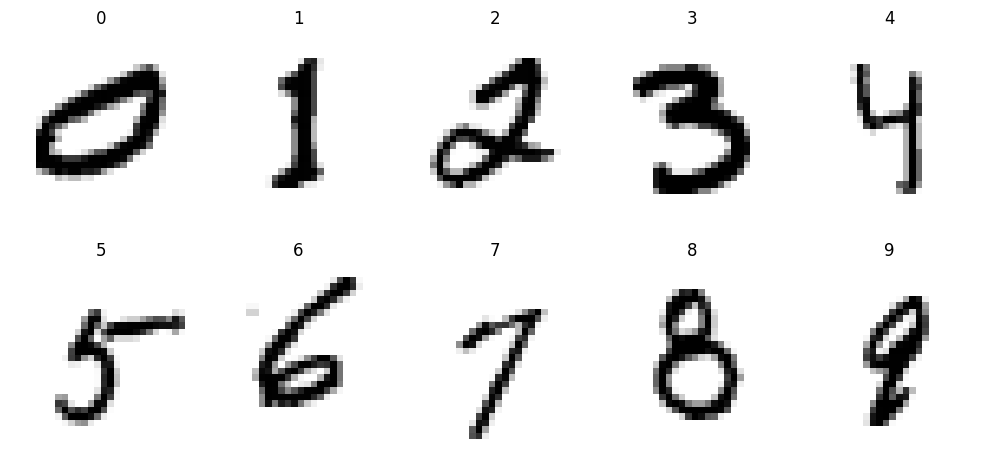

In [2]:
images, labels, test_images, y_test = load_mnist()
subset, _ = train_test_split(np.arange(len(labels)), train_size=15000, stratify=labels, random_state=SEED)
fit, val = train_test_split(subset, train_size=12000, stratify=labels[subset], random_state=SEED)
X_fit = images[fit].reshape(-1, 784).astype(np.float32) / 255.
X_val = images[val].reshape(-1, 784).astype(np.float32) / 255.
X_test = test_images.reshape(-1, 784).astype(np.float32) / 255.
y_fit, y_val = labels[fit], labels[val]
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for digit, ax in enumerate(axes.flat):
    row = np.flatnonzero(y_fit == digit)[0]
    ax.imshow(images[fit[row]], cmap="gray_r"); ax.set_title(str(digit)); ax.axis("off")
plt.tight_layout(); plt.show()

## Select tree depth on validation images

We compare three candidate depths, with at least five fitting images per leaf. Ties go to the smaller depth. The forest and network settings in the following cell are fixed teaching choices. The test images take no part in these choices.

In [3]:
depths = [3, 10, 18]
trees = [DecisionTreeClassifier(max_depth=d, min_samples_leaf=5, random_state=SEED).fit(X_fit, y_fit)
         for d in depths]
scores = [accuracy_score(y_val, tree.predict(X_val)) for tree in trees]
selected_tree = trees[int(np.argmax(scores))]
display(pd.DataFrame({"depth": depths, "validation accuracy": scores}))

,depth,validation accuracy
0,3,0.449000
1,10,0.815000
2,18,0.821333


## Fit a forest and a network

Scikit-learn handles training internally. The forest combines randomized trees. The network has one hidden layer of 64 ReLU units and ten probability outputs. `early_stopping=True` uses an internal subset of the fitting images and stops when that internal score ceases to improve. The external validation images remain available for inspection.

In [4]:
models = {
    "Tree": selected_tree,
    "Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=2, random_state=SEED, n_jobs=2),
    "Network": MLPClassifier(hidden_layer_sizes=(64,), alpha=1., batch_size=128, max_iter=150,
                             early_stopping=True, n_iter_no_change=12, random_state=SEED)}
for name in ["Forest", "Network"]:
    models[name].fit(X_fit, y_fit)
display(pd.DataFrame({"model": list(models), "validation accuracy": [accuracy_score(
    y_val, model.predict(X_val)) for model in models.values()]}))

,model,validation accuracy
0,Tree,0.821333
1,Forest,0.954000
2,Network,0.940333


## Evaluate the fixed models

Accuracy is the fraction of correctly classified images. The baseline predicts the most frequent fitting digit. Each confusion matrix shows which true digits are assigned to each predicted digit. The configurations and tuning budgets are deliberately small, so this is an illustration of the methods on a shared input, rather than a comprehensive image benchmark.

,model,accuracy
0,Baseline,0.1135
1,Tree,0.8221
2,Forest,0.9506
3,Network,0.9415


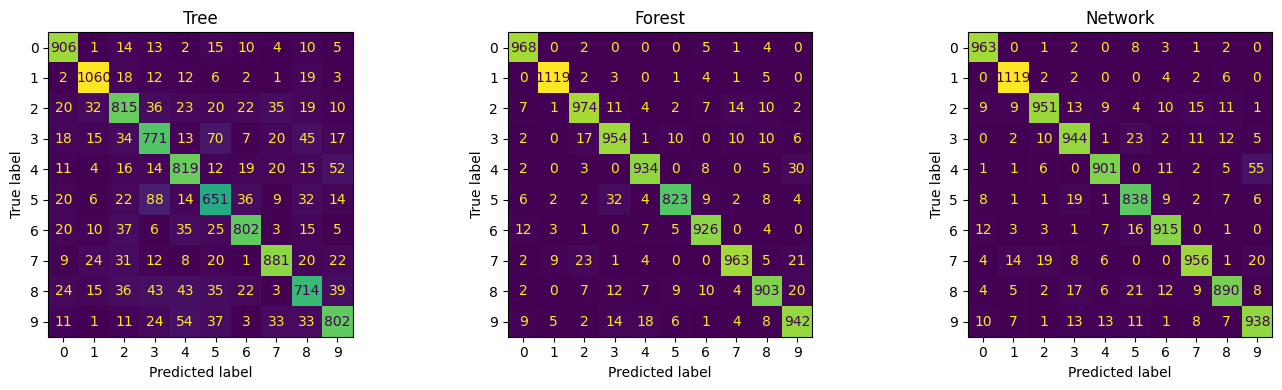

In [5]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_fit, y_fit)
rows = []
for name, model in {"Baseline": baseline, **models}.items():
    rows.append(dict(model=name, accuracy=float(accuracy_score(y_test, model.predict(X_test)))))
display(pd.DataFrame(rows))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()
with open("results/simple_mnist.json", "w") as stream:
    json.dump(dict(test=rows, selected_depth=int(selected_tree.max_depth),
                   fitting_size=len(fit), validation_size=len(val), test_size=len(y_test)), stream, indent=2)

## Display the same images with all predictions

The first twelve test images are fixed independently of model success. T, F and N denote tree, forest and network. Inspect a disagreement, then use `predict_proba` to see how strongly each model favours its answer.

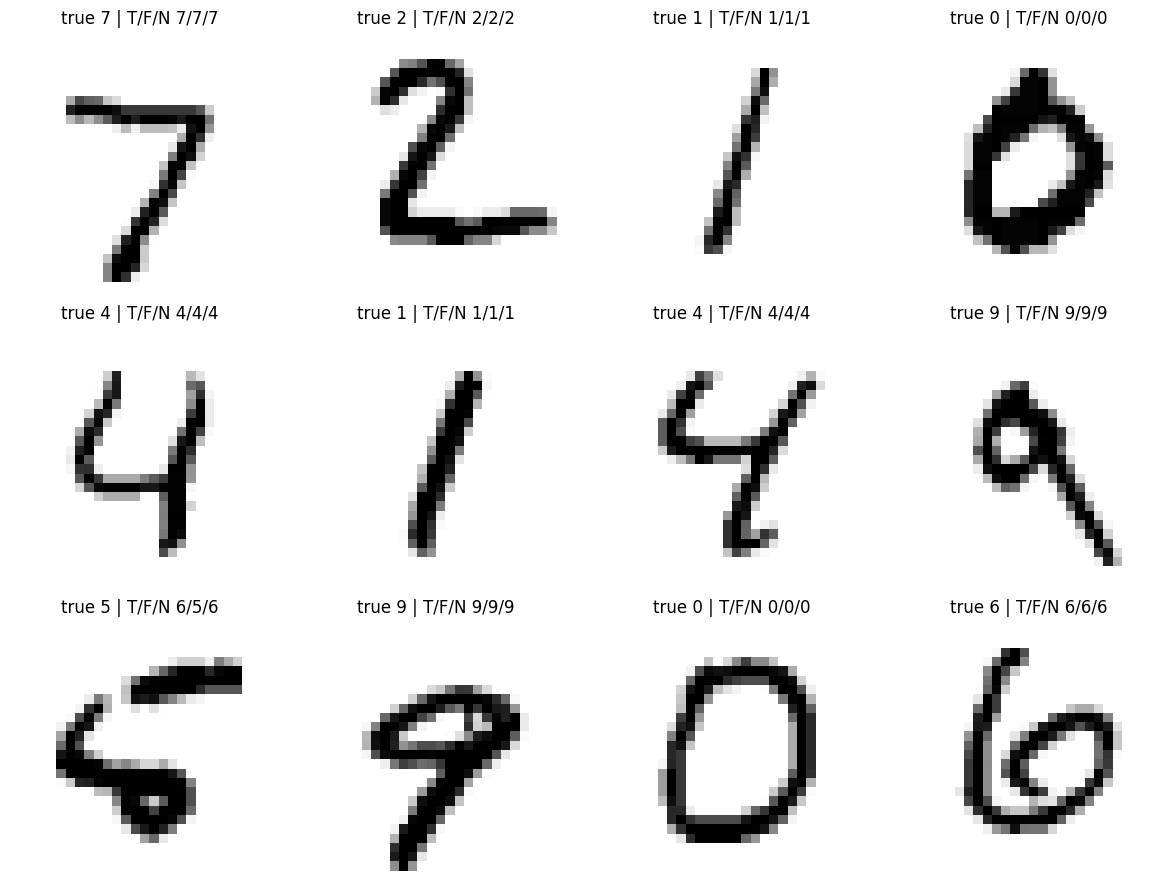

,Tree,Forest,Network
0,0.0,0.0,0.000672
1,0.0,0.0,0.000030
2,0.0,0.0,0.000935
3,0.0,0.0,0.003329
4,0.0,0.0,0.000028
5,0.0,0.0,0.001164
6,0.0,0.0,0.000003
7,1.0,1.0,0.990134
8,0.0,0.0,0.000180
9,0.0,0.0,0.003524


In [6]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for i, ax in enumerate(axes.flat):
    ax.imshow(test_images[i], cmap="gray_r")
    answers = [int(model.predict(X_test[i:i+1])[0]) for model in models.values()]
    ax.set_title(f"true {y_test[i]} | T/F/N {answers[0]}/{answers[1]}/{answers[2]}", fontsize=12)
    ax.axis("off")
fig.tight_layout()
fig.savefig("figures/mnist_three_model_predictions.pdf", bbox_inches="tight")
fig.savefig("figures/mnist_three_model_predictions.png", dpi=150, bbox_inches="tight")
plt.show()
display(pd.DataFrame({name: model.predict_proba(X_test[:1])[0] for name, model in models.items()}))

## Practice

Explain why a high probability can accompany a wrong prediction. State what a tree question about one pixel measures. Predict how moving a digit by two pixels might affect the three models.

<details><summary>Feedback</summary>

Probabilities are model estimates whose reliability needs independent evaluation. A pixel question tests brightness at one fixed location. Moving an image changes its input coordinates. These three classifiers have no built-in convolutional weight sharing, so shift behaviour has to be learned from examples or addressed with another architecture.

</details>